<a href="https://colab.research.google.com/github/quentinbxf/backtest-sp500/blob/main/Backtest_SP500_Python_QuentinB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Backtest d'une stratégie de moyennes mobiles sur le S&P 500
**Quentin Beroual**

Ce notebook reproduit en Python le backtest construit dans Excel, puis vérifie que les deux donnent les mêmes chiffres.

**Règle testée :** si la moyenne mobile 50 jours est au-dessus de la moyenne mobile 200 jours à la clôture, on est investi le lendemain ; sinon, on est en cash.


In [1]:
!pip install -q -U yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Outils prêts")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 4.8 MB/s eta 0:00:00
Outils prêts


In [2]:
data = yf.download("^GSPC", start="1990-01-01", end="2026-10-10", progress=False, auto_adjust=False)
prix = data["Close"].squeeze().dropna()   # on garde uniquement la colonne des cours de clôture

print("Nombre de séances :", len(prix))
print("Première date :", prix.index[0].date(), "| Dernière date :", prix.index[-1].date())
print("Dernière clôture :", round(float(prix.iloc[-1]), 2))

Nombre de séances : 9261
Première date : 1990-01-02 | Dernière date : 2026-10-09
Dernière clôture : 7811.54


In [3]:
MM_COURTE = 50      # moyenne mobile courte, en jours de bourse
MM_LONGUE = 200     # moyenne mobile longue, en jours de bourse
CAPITAL = 10_000    # capital de départ, en dollars
FRAIS = 0.001       # 0,10 % de frais à chaque achat ou vente
TAUX_SR = 0.0       # taux sans risque annuel (rémunération du cash et ratio de Sharpe)
JOURS_AN = 252      # nombre de jours de bourse dans une année

In [4]:
df = pd.DataFrame({"cloture": prix})
df["rendement"] = df["cloture"].pct_change()
df["mm_courte"] = df["cloture"].rolling(MM_COURTE).mean()
df["mm_longue"] = df["cloture"].rolling(MM_LONGUE).mean()
df["signal"] = (df["mm_courte"] > df["mm_longue"]).astype(int)

# on démarre le backtest le jour où la moyenne mobile la plus longue est calculable
debut = max(MM_COURTE, MM_LONGUE) - 1      # Python compte les lignes à partir de 0
bt = df.iloc[debut:].copy()

bt["position"] = bt["signal"].shift(1)                              # signal de la veille
bt["transaction"] = bt["position"].fillna(0).diff().abs().fillna(0) # 1 quand la position change

bt.loc["2007-12-17":"2007-12-27", ["cloture", "mm_courte", "mm_longue", "signal", "position", "transaction"]].round(2)

,cloture,mm_courte,mm_longue,signal,position,transaction
Date,,,,,,
2007-12-17,1445.90,1494.48,1487.02,1,1.0,0.0
2007-12-18,1454.98,1492.53,1487.32,1,1.0,0.0
2007-12-19,1453.00,1490.29,1487.63,1,1.0,0.0
2007-12-20,1460.12,1488.24,1487.92,1,1.0,0.0
2007-12-21,1484.46,1486.84,1488.33,0,1.0,0.0
2007-12-24,1496.45,1485.54,1488.77,0,0.0,1.0
2007-12-26,1497.66,1484.52,1489.37,0,0.0,0.0
2007-12-27,1476.27,1483.27,1489.82,0,0.0,0.0


In [5]:
bt["rdt_strategie"] = bt["position"] * bt["rendement"] + (1 - bt["position"]) * TAUX_SR / JOURS_AN - bt["transaction"] * FRAIS
bt["rdt_buy_hold"] = bt["rendement"]
bt.iloc[1, bt.columns.get_loc("rdt_buy_hold")] -= FRAIS   # frais d'achat du buy & hold, le premier jour
bt.iloc[0, bt.columns.get_loc("rdt_strategie")] = 0       # premier jour : point de départ, pas de rendement
bt.iloc[0, bt.columns.get_loc("rdt_buy_hold")] = 0

bt["valeur_strategie"] = CAPITAL * (1 + bt["rdt_strategie"]).cumprod()
bt["valeur_buy_hold"] = CAPITAL * (1 + bt["rdt_buy_hold"]).cumprod()

print("Valeur finale stratégie :", round(bt["valeur_strategie"].iloc[-1]), "$")
print("Valeur finale buy & hold :", round(bt["valeur_buy_hold"].iloc[-1]), "$")

Valeur finale stratégie : 174860 $
Valeur finale buy & hold : 257350 $


In [6]:
def indicateurs(rendements, valeur):
    annees = (valeur.index[-1] - valeur.index[0]).days / 365.25
    cagr = (valeur.iloc[-1] / CAPITAL) ** (1 / annees) - 1
    volatilite = rendements.std() * np.sqrt(JOURS_AN)
    sharpe = (rendements.mean() * JOURS_AN - TAUX_SR) / volatilite
    perte_max = (valeur / valeur.cummax() - 1).min()
    return {"CAGR": cagr, "Volatilité": volatilite, "Sharpe": sharpe,
            "Perte maximale": perte_max, "Calmar": cagr / abs(perte_max)}

# on enlève le premier jour (point de départ) pour les statistiques, comme dans Excel
strat = indicateurs(bt["rdt_strategie"].iloc[1:], bt["valeur_strategie"])
bh = indicateurs(bt["rdt_buy_hold"].iloc[1:], bt["valeur_buy_hold"])

resultats = pd.DataFrame({"Stratégie 50/200": strat, "Buy & hold": bh})
print("Nombre de transactions :", int(bt["transaction"].sum()))
print("Temps investi :", f"{bt['position'].mean():.1%}")
resultats.style.format({"Stratégie 50/200": "{:.4f}", "Buy & hold": "{:.4f}"})

Nombre de transactions : 31
Temps investi : 76.6%


,Stratégie 50/200,Buy & hold
CAGR,0.0828,0.0945
Volatilité,0.1313,0.1800
Sharpe,0.6721,0.5920
Perte maximale,-0.3392,-0.5678
Calmar,0.2440,0.1664


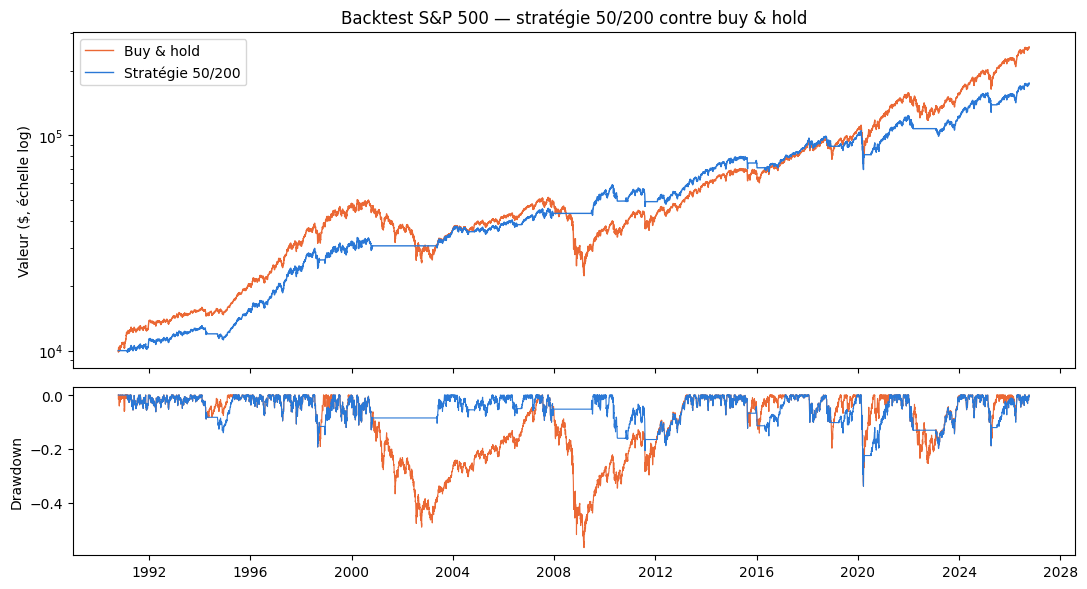

In [7]:
fig, (haut, bas) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

haut.plot(bt.index, bt["valeur_buy_hold"], color="#eb6834", lw=1, label="Buy & hold")
haut.plot(bt.index, bt["valeur_strategie"], color="#2a78d6", lw=1, label="Stratégie 50/200")
haut.set_yscale("log")
haut.set_ylabel("Valeur ($, échelle log)")
haut.legend()
haut.set_title("Backtest S&P 500 — stratégie 50/200 contre buy & hold")

for col, couleur in (("valeur_buy_hold", "#eb6834"), ("valeur_strategie", "#2a78d6")):
    drawdown = bt[col] / bt[col].cummax() - 1
    bas.plot(bt.index, drawdown, color=couleur, lw=0.8)
bas.set_ylabel("Drawdown")

plt.tight_layout()
plt.show()

In [8]:
def backtest(court, long, frais):
    d = pd.DataFrame({"cloture": prix})
    d["rendement"] = d["cloture"].pct_change()
    d["signal"] = (d["cloture"].rolling(court).mean() > d["cloture"].rolling(long).mean()).astype(int)
    b = d.iloc[max(court, long) - 1:].copy()
    b["position"] = b["signal"].shift(1)
    b["transaction"] = b["position"].fillna(0).diff().abs().fillna(0)
    b["rdt"] = b["position"] * b["rendement"] + (1 - b["position"]) * TAUX_SR / JOURS_AN - b["transaction"] * frais
    b.iloc[0, b.columns.get_loc("rdt")] = 0
    valeur = CAPITAL * (1 + b["rdt"]).cumprod()
    res = indicateurs(b["rdt"].iloc[1:], valeur)
    res["Transactions"] = int(b["transaction"].sum())
    return res

reglages = {"20/100": (20, 100, 0.001), "50/200": (50, 200, 0.001),
            "100/300": (100, 300, 0.001), "50/200, frais 0,5 %": (50, 200, 0.005)}
robustesse = pd.DataFrame({nom: backtest(*p) for nom, p in reglages.items()}).T
robustesse.style.format({"CAGR": "{:.1%}", "Volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                         "Perte maximale": "{:.1%}", "Calmar": "{:.2f}", "Transactions": "{:.0f}"})

,CAGR,Volatilité,Sharpe,Perte maximale,Calmar,Transactions
20/100,5.1%,11.7%,0.48,-36.9%,0.14,109
50/200,8.3%,13.1%,0.67,-33.9%,0.24,31
100/300,9.1%,13.9%,0.70,-33.9%,0.27,19
"50/200, frais 0,5 %",7.9%,13.1%,0.65,-33.9%,0.23,31
